In [1]:
!pip install -q scikit-learn==1.7.2 xgboost==3.4.1 shap

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd, numpy as np, joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

df2 = pd.read_csv("data.csv")

def assign_risk(label):
    if label == "monitor":
        return "Low"
    if "ponding_hotspot" in label:
        return "High"
    factors = label.split("|")
    if len(factors) >= 2:
        return "High"
    return "Medium"

df2["risk_level"] = df2["risk_labels"].apply(assign_risk)

features = ["latitude", "longitude", "elevation_m", "land_use", "soil_group",
            "drainage_density_km_per_km2", "storm_drain_proximity_m",
            "storm_drain_type", "historical_rainfall_intensity_mm_hr",
            "return_period_years"]

X = df2[features]
y = df2["risk_level"]

# Same split as Member 1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Load the SAVED preprocessor and model (do not retrain)
preprocessor = joblib.load("flood_preprocessor.pkl")
model = joblib.load("xgboost_flood_model.pkl")

class_names = {0: "High", 1: "Low", 2: "Medium"}
X_test_processed = preprocessor.transform(X_test)
y_pred = pd.Series(model.predict(X_test_processed)).map(class_names).values

print("Test rows:", X_test.shape[0])
print("Accuracy:", accuracy_score(y_test, y_pred))

Test rows: 593
Accuracy: 0.9713322091062394


              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       399
      Medium       0.91      0.96      0.94       122
        High       0.92      0.85      0.88        72

    accuracy                           0.97       593
   macro avg       0.95      0.93      0.94       593
weighted avg       0.97      0.97      0.97       593



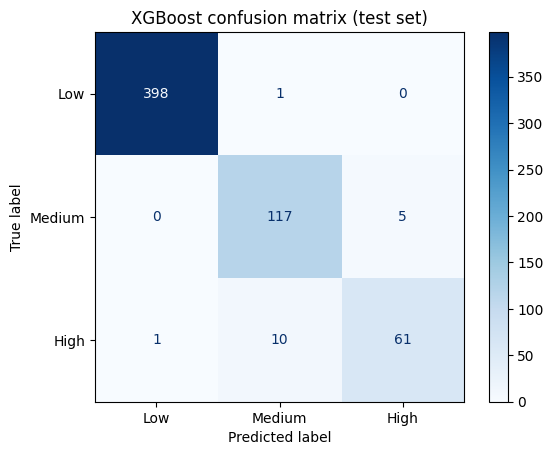

In [3]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

order = ["Low", "Medium", "High"]

print(classification_report(y_test, y_pred, labels=order))

cm = confusion_matrix(y_test, y_pred, labels=order)
ConfusionMatrixDisplay(cm, display_labels=order).plot(cmap="Blues")
plt.title("XGBoost confusion matrix (test set)")
plt.show()

In [4]:
import shap

feature_names = [n.split("__", 1)[-1] for n in preprocessor.get_feature_names_out()]

X_dense = X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else np.asarray(X_test_processed)

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_dense)
shap_values.feature_names = feature_names

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (593, 26, 3)


['latitude', 'longitude', 'elevation_m', 'drainage_density_km_per_km2', 'storm_drain_proximity_m', 'historical_rainfall_intensity_mm_hr', 'return_period_years', 'land_use_Commercial', 'land_use_Green', 'land_use_Industrial', 'land_use_Informal', 'land_use_Institutional', 'land_use_Mixed', 'land_use_Residential', 'land_use_Roads', 'land_use_Water', 'soil_group_A', 'soil_group_B', 'soil_group_C', 'soil_group_D', 'soil_group_nan', 'storm_drain_type_CurbInlet', 'storm_drain_type_GratedInlet', 'storm_drain_type_Manhole', 'storm_drain_type_OpenChannel', 'storm_drain_type_nan']


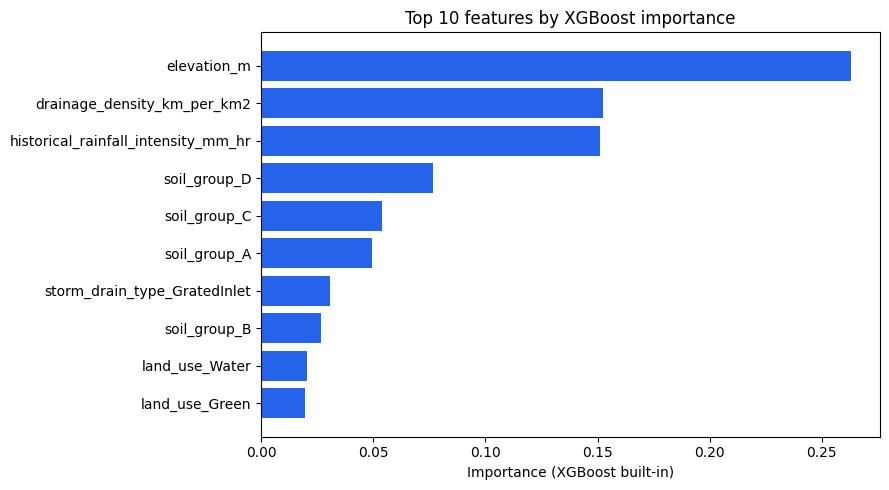

In [5]:
import matplotlib.pyplot as plt

print(feature_names)

imp_df = pd.DataFrame({"Feature": feature_names,
                       "Importance": model.feature_importances_})
top = imp_df.sort_values("Importance").tail(10)

plt.figure(figsize=(9, 5))
plt.barh(top["Feature"], top["Importance"], color="#2563eb")
plt.xlabel("Importance (XGBoost built-in)")
plt.title("Top 10 features by XGBoost importance")
plt.tight_layout()
plt.show()

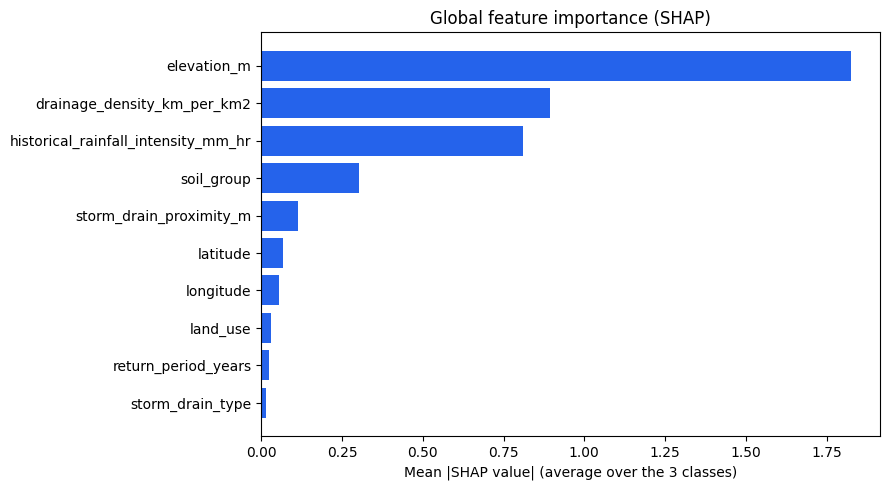

                                      High    Low  Medium  Average
elevation_m                          1.463  2.938   1.072    1.824
drainage_density_km_per_km2          1.036  1.116   0.525    0.893
historical_rainfall_intensity_mm_hr  0.703  1.231   0.495    0.810
soil_group                           0.512  0.078   0.321    0.304
storm_drain_proximity_m              0.143  0.042   0.154    0.113
latitude                             0.098  0.073   0.033    0.068
longitude                            0.091  0.011   0.063    0.055
land_use                             0.026  0.033   0.027    0.029
return_period_years                  0.023  0.004   0.042    0.023
storm_drain_type                     0.025  0.003   0.015    0.014


In [6]:
class_names = {0: "High", 1: "Low", 2: "Medium"}

def group_name(n):
    for f in sorted(features, key=len, reverse=True):
        if n == f or n.startswith(f + "_"):
            return f
    return n

groups = [group_name(n) for n in feature_names]

def grouped_importance(c):
    arr = pd.DataFrame(shap_values.values[:, :, c], columns=groups)
    arr = arr.T.groupby(level=0).sum().T        # one column per original input
    return arr.abs().mean()                      # mean |SHAP|

imp = pd.DataFrame({class_names[c]: grouped_importance(c) for c in range(3)})
imp["Average"] = imp.mean(axis=1)
imp = imp.sort_values("Average")

plt.figure(figsize=(9, 5))
plt.barh(imp.index, imp["Average"], color="#2563eb")
plt.xlabel("Mean |SHAP value| (average over the 3 classes)")
plt.title("Global feature importance (SHAP)")
plt.tight_layout()
plt.show()

print(imp.sort_values("Average", ascending=False).round(3))

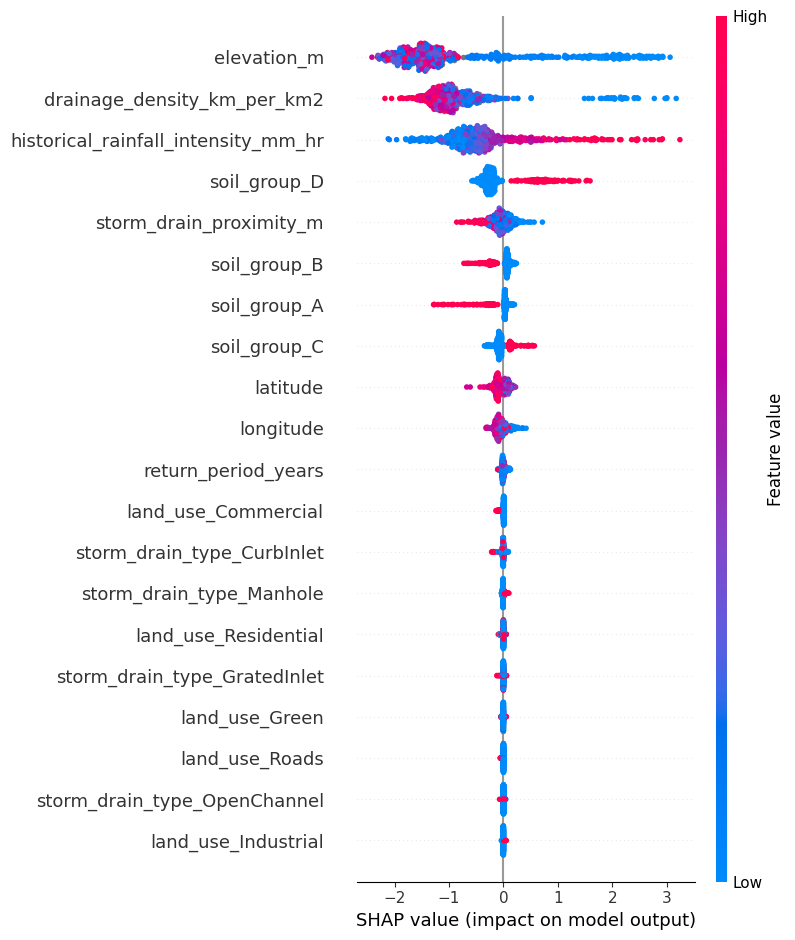

In [7]:
shap.summary_plot(shap_values.values[:, :, 0], X_dense,
                  feature_names=feature_names, show=True)

--- Row 1: true = High, predicted = High ---


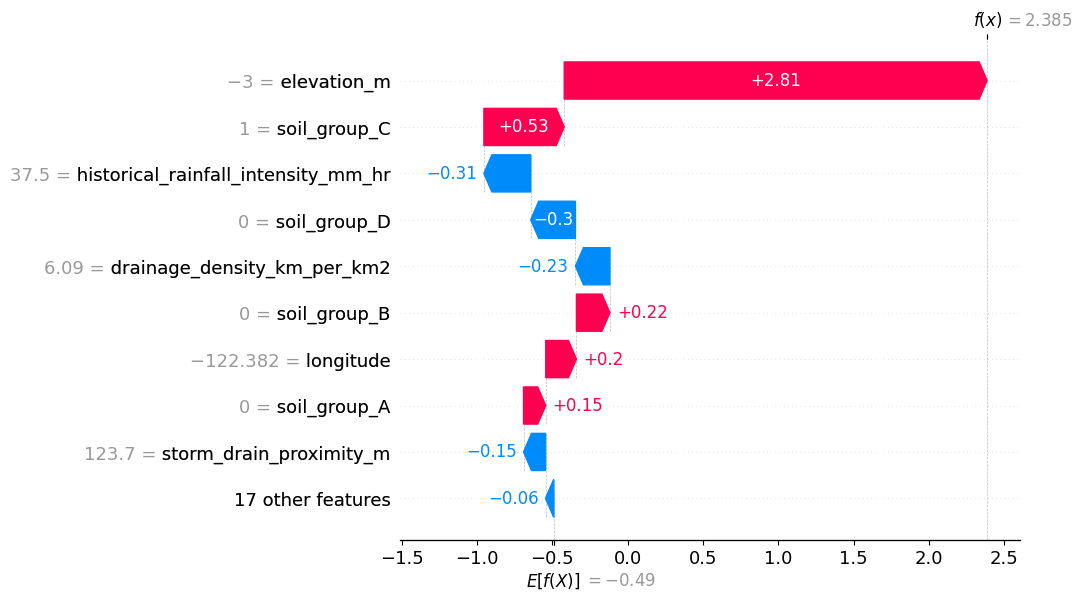

--- Row 3: true = Medium, predicted = Medium ---


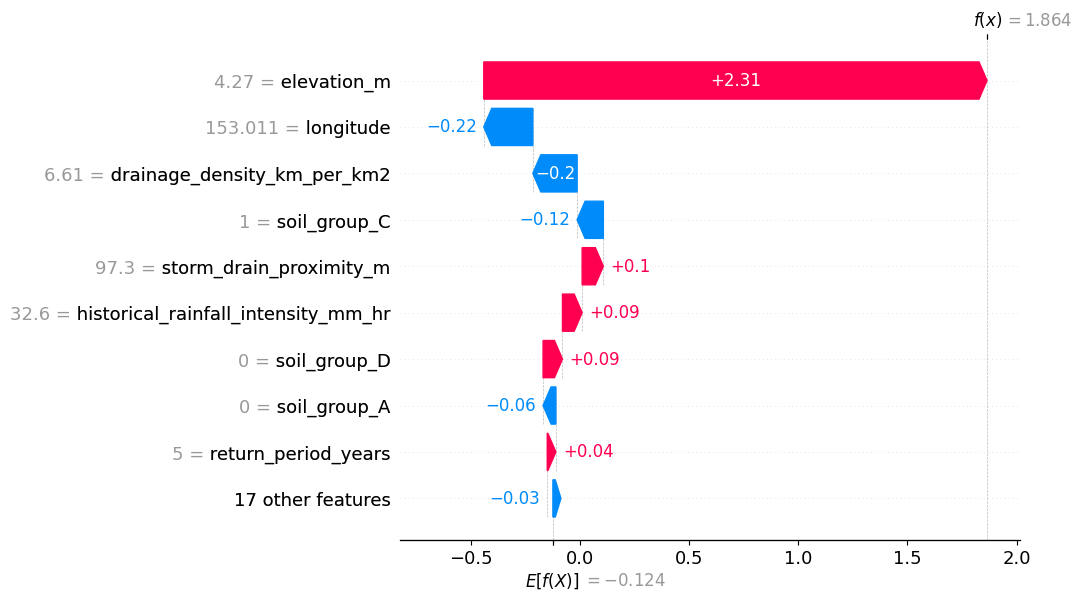

--- Row 0: true = Low, predicted = Low ---


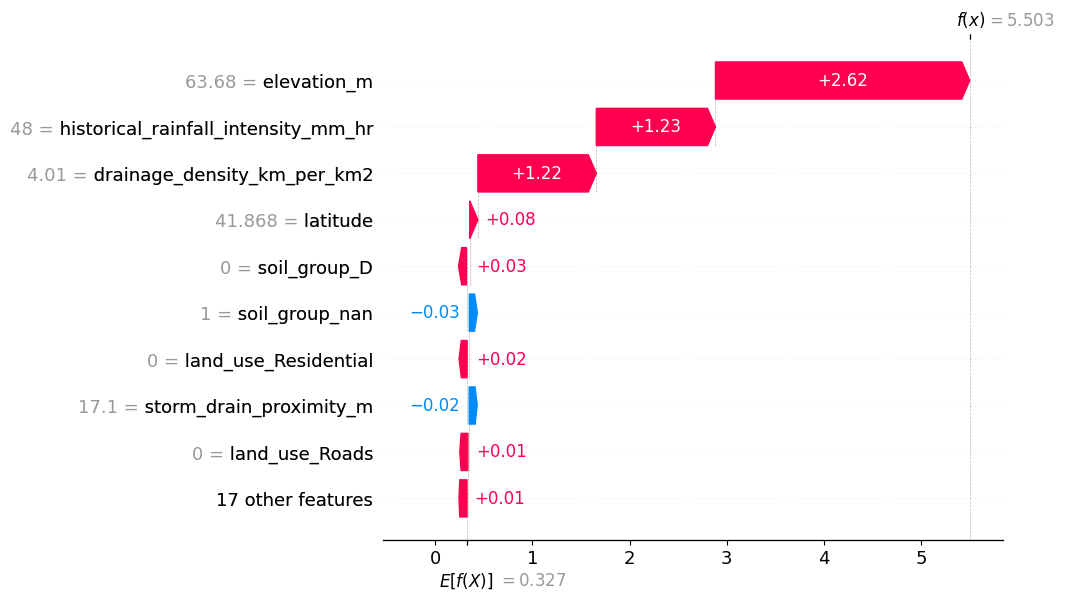

In [8]:
num = ["latitude", "longitude", "elevation_m", "drainage_density_km_per_km2",
       "storm_drain_proximity_m", "historical_rainfall_intensity_mm_hr", "return_period_years"]
shap_values.data = shap_values.data.copy()
shap_values.data[:, :7] = X_test[num].to_numpy(dtype=float)

y_true = y_test.values
cls = {"High": 0, "Low": 1, "Medium": 2}

for name in ["High", "Medium", "Low"]:
    i = np.where((y_true == name) & (y_pred == name))[0][0]
    print(f"--- Row {i}: true = {y_true[i]}, predicted = {y_pred[i]} ---")
    shap.plots.waterfall(shap_values[i, :, cls[name]], max_display=10)

Misclassified rows: 17 of 593
Predicted  High  Low  Medium
True                        
High          0    1      10
Low           0    0       1
Medium        5    0       0
--- Row 37: true = High, predicted = Medium ---
{'latitude': -36.986417, 'longitude': 174.673069, 'elevation_m': -3.0, 'drainage_density_km_per_km2': 5.73, 'storm_drain_proximity_m': 61.7, 'historical_rainfall_intensity_mm_hr': 22.7, 'return_period_years': 2}


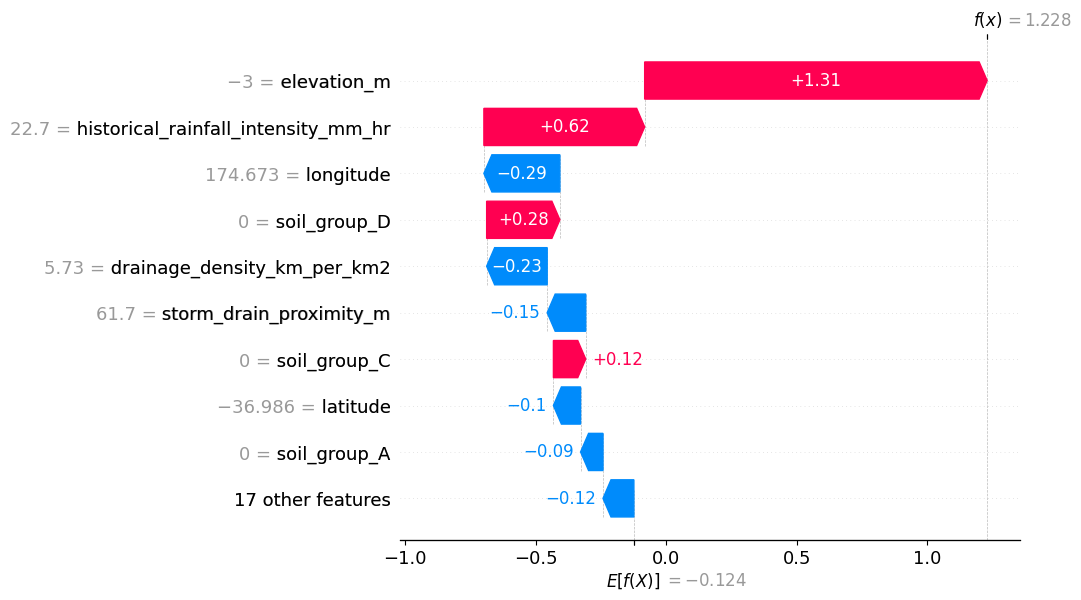

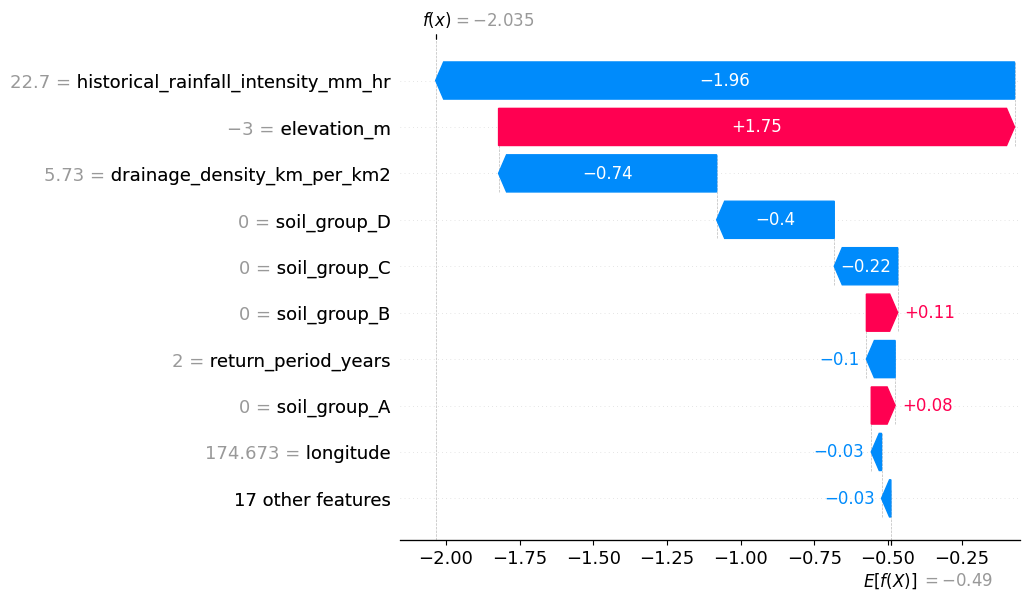

--- Row 65: true = Medium, predicted = High ---
{'latitude': 41.473524, 'longitude': 2.169929, 'elevation_m': 8.47, 'drainage_density_km_per_km2': 2.65, 'storm_drain_proximity_m': 274.4, 'historical_rainfall_intensity_mm_hr': 30.6, 'return_period_years': 10}


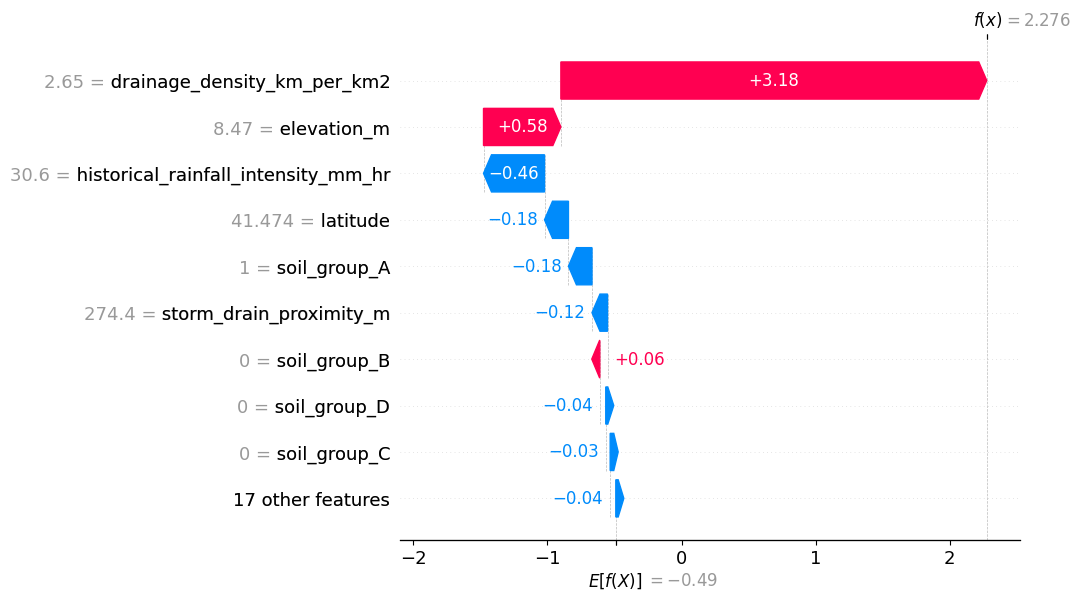

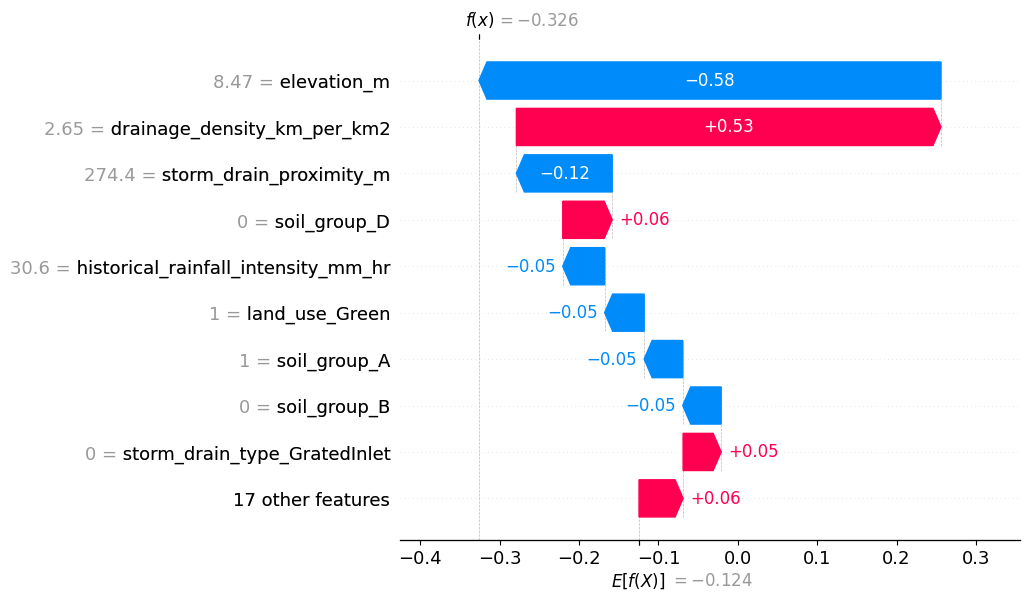

In [9]:
wrong = np.where(y_true != y_pred)[0]
print("Misclassified rows:", len(wrong), "of", len(y_true))
print(pd.crosstab(pd.Series(y_true[wrong], name="True"),
                  pd.Series(y_pred[wrong], name="Predicted")))

# Explain the first 2 mistakes: score for the TRUE class and for the PREDICTED class
for i in wrong[:2]:
    print(f"--- Row {i}: true = {y_true[i]}, predicted = {y_pred[i]} ---")
    print(X_test.iloc[i][num].round(2).to_dict())
    shap.plots.waterfall(shap_values[i, :, cls[y_pred[i]]], max_display=10)
    shap.plots.waterfall(shap_values[i, :, cls[y_true[i]]], max_display=10)

In [10]:
proba = model.predict_proba(X_test_processed)
for i in wrong:
    p = {class_names[k]: round(float(proba[i][k]), 2) for k in range(3)}
    print(f"Row {i}: true={y_true[i]}, predicted={y_pred[i]}, probabilities={p}")

Row 37: true=High, predicted=Medium, probabilities={'High': 0.04, 'Low': 0.0, 'Medium': 0.96}
Row 65: true=Medium, predicted=High, probabilities={'High': 0.93, 'Low': 0.0, 'Medium': 0.07}
Row 105: true=High, predicted=Medium, probabilities={'High': 0.18, 'Low': 0.0, 'Medium': 0.82}
Row 201: true=Medium, predicted=High, probabilities={'High': 0.57, 'Low': 0.01, 'Medium': 0.42}
Row 208: true=Medium, predicted=High, probabilities={'High': 0.64, 'Low': 0.0, 'Medium': 0.36}
Row 229: true=High, predicted=Medium, probabilities={'High': 0.29, 'Low': 0.01, 'Medium': 0.7}
Row 241: true=High, predicted=Medium, probabilities={'High': 0.08, 'Low': 0.0, 'Medium': 0.92}
Row 286: true=High, predicted=Medium, probabilities={'High': 0.38, 'Low': 0.01, 'Medium': 0.62}
Row 371: true=High, predicted=Medium, probabilities={'High': 0.13, 'Low': 0.0, 'Medium': 0.86}
Row 376: true=High, predicted=Low, probabilities={'High': 0.29, 'Low': 0.66, 'Medium': 0.05}
Row 408: true=High, predicted=Medium, probabilities=

In [11]:
print(df2["elevation_m"].value_counts().head(5))
print()
print(df2.columns.tolist())

elevation_m
-3.00     249
 2.80       4
 10.38      4
 21.62      4
 7.31       4
Name: count, dtype: int64

['segment_id', 'city_name', 'admin_ward', 'latitude', 'longitude', 'catchment_id', 'elevation_m', 'dem_source', 'land_use', 'soil_group', 'drainage_density_km_per_km2', 'storm_drain_proximity_m', 'storm_drain_type', 'rainfall_source', 'historical_rainfall_intensity_mm_hr', 'return_period_years', 'risk_labels', 'risk_level']


In [12]:
placeholder = df2["elevation_m"] == -3
print("Rows with elevation -3:", placeholder.sum(), "of", len(df2))
print()
print(df2.loc[placeholder, "dem_source"].value_counts())
print()
print(df2.loc[~placeholder, "dem_source"].value_counts())
print()
print(pd.crosstab(placeholder.rename("elevation is -3"), df2["risk_level"]))

Rows with elevation -3: 249 of 2963

dem_source
Copernicus_GLO-30_v2023    83
SRTM_1arc                  58
SRTM_3arc                  48
Copernicus_EEA-10_v5       40
Copernicus_GLO-90_v2022    20
Name: count, dtype: int64

dem_source
Copernicus_GLO-30_v2023    786
SRTM_1arc                  725
SRTM_3arc                  502
Copernicus_EEA-10_v5       460
Copernicus_GLO-90_v2022    241
Name: count, dtype: int64

risk_level       High   Low  Medium
elevation is -3                    
False             234  1991     489
True              127     0     122


## Observations and conclusion

**Model performance.** On the 593 test rows (same 80/20 stratified split as Member 1,
random_state=42) the saved XGBoost model reaches 97.13% accuracy. Low risk is classified
almost perfectly (f1 = 1.00). High risk is the weakest class (recall 0.85): 11 of 72
true High cases were missed.

**Global feature importance (SHAP, High class).** Elevation (1.46), drainage density (1.04)
and rainfall intensity (0.70) are the most influential inputs, followed by soil group (0.51).
Latitude, longitude, land use, return period and storm drain type have very small influence
(all below 0.1). Low elevation, low drainage density, high rainfall and soil group D push
predictions toward High; soil groups A and B push away from it.

**Individual explanations.** In the correctly classified examples a single input
(elevation) gave the largest contribution, and the waterfall plots add up from the base
value to the final score of the predicted class.

**Error analysis.** 17 of 593 rows (2.9%) were misclassified; 15 of these are confusions
between High and Medium, so the model rarely confuses the extremes. 8 of the 17 errors were
made with a probability of 0.91 or more, so the model's confidence is not a reliable
indicator of its mistakes. In Row 65, low drainage density (+3.18) outweighed moderate
rainfall (-0.46) and pushed a Medium case to High.

**Limitations.** The risk labels were created by a rule applied to the risk_labels column,
so the model may be learning that rule; elevation, drainage density and rainfall match the
label names. SHAP explains the model, not real-world causes. The dataset covers locations
worldwide, so the Indian city presets in the app are demonstrations, not validated local
forecasts. Water level, soil moisture and humidity are not model inputs.Elevation is recorded as exactly -3.0 m in 249 rows, far more often than any other value,
so it appears to be a placeholder (possibly from the DEM source) rather than a real
measurement. The model may treat this value as a strong signal. No time-series analysis
was done because the dataset has no date or time column.

**Conclusion.** The model is accurate on this dataset and its predictions can be explained
mainly by elevation, drainage density and rainfall. The weaker High recall should be
improved before any real use.